# Figure 6: Change-Point Summary

Translation of `Figure06_cpSummary.m`

## What this notebook does

Characterizes how participants adjust their decision bounds in response to a **change point (CP)**
in the generative process. In CP trials the SNR shifts mid-block at a random time; the optimal
response is to increase or decrease the bound to maximize reward rate (RR) at the new SNR.

All statistics are computed once, early in the notebook, and plotted only once — in the
**Formatted figure** section near the end. There are no separate "preview" plots above; the
computation cells below print their results as text so you can sanity-check numbers before the
combined figure is built.

**3-row, 2-column figure layout** (columns = LowHigh / HighLow CP directions). Each row uses its
own, deliberately distinct visual encoding, since the three rows show unrelated quantities:

- **Row 1 — Example RR curve**: One example subject's smoothed RR vs. bound curve at their
  actual CP step, with markers at the pre-CP bound (open circle), optimal bound (blue ★), and
  post-CP bound (filled black circle).
- **Row 2 — Bound change vs. RR gradient**: one panel per condition. The x-axis is `gradient`
  — the RR secant slope from the pre-CP bound to the RR-optimal bound, signed automatically
  (positive when the RR-optimal bound is above the pre-CP bound, negative when it's below).
  Point fill color encodes the subject's raw pre-CP bound on a dedicated blue-red gradient
  (shared scale across both panels). Each panel is annotated with a single statistic: the
  precision-weighted, nonparametric correlation between gradient and bound change (see
  "Statistical tests" below).
- **Row 3 — Panels E, F: pre- vs. post-CP bound (LowHigh vs. HighLow)**: same two conditions in
  both panels, compared before (E) and after (F) the change point, so the two panels are directly
  comparable. Per-subject SEM errorbars in both directions; each panel annotated with a
  precision-weighted, nonparametric paired-difference test (see "Statistical tests" below and
  "Row 3" further down for why this uses the pre-/post-CP bounds rather than the stable, no-CP
  blocks).

## Statistical tests

Computed once, right after the RR benchmark, and used both as panel annotations and throughout
"Key findings" below. Every test in this notebook is nonparametric; where a test also needs to
account for the fact that different subjects' bound/Δ estimates rest on very different numbers of
trials (and are therefore not equally reliable), it's made precision-weighted via a permutation
test rather than switching to a parametric (Gaussian-assumption) test:

1. **Precision-weighted Spearman correlation, bound change vs. RR gradient**
   (`weighted_spearman_stats`) — rank-transform gradient and Δ (as for ordinary Spearman), then
   compute a precision-weighted Pearson correlation on those ranks (weights = 1/SEM_Δ²); p-value
   from a permutation test (shuffle the gradient/Δ pairing, keeping each weight attached to its
   own Δ), not a t-test. One pooled statistic per condition (panels C/D).
2. **Precision-weighted paired-difference test, LowHigh vs. HighLow bound** (`panelEF_stats`) —
   H0: the paired difference (HighLow − LowHigh) has a center of zero. There's no standard
   "weighted Wilcoxon", so this uses a sign-flip permutation test on the precision-weighted mean
   difference (weights = 1/SEM_diff²): the null distribution comes from randomly flipping the
   sign of each subject's difference (valid under H0: each difference symmetric about zero, the
   same assumption behind an ordinary sign test/Wilcoxon), not from assuming normality. Computed
   separately for the pre-CP (panel E) and post-CP (panel F) bound pairs.
3. **Spearman correlation, bound change vs. raw pre-CP bound** (`spearman_prebound`) — an
   independent, unweighted, notebook-only diagnostic (not panel-annotated), since pre-CP bound is
   not the same quantity as gradient.

## Data requirements

Per-subject CP bound summaries are computed directly from raw data at the top of this notebook
(`get_data_table(task_type='MXSC')` + `pigeon.data.get_bound_summaries_wcp`) --
fields: `LowHigh` (n_subjects × 2: [pre-CP bound, post-CP bound] for Low→High transitions),
`HighLow`, `Low`, `High` (the latter two are the stable, no-CP blocks -- kept only for the
`nonfinite_bound` reconstruction check further down, no longer used by panels E/F themselves),
`CPLowHigh` (CP step per subject), `CPHighLow`, and `SEM*` counterparts of each bound field (used
for the Row 3 errorbars and the panel E/F weights).

Before any of the above is computed, every block's first 10 trials (`trial_number <= 10`) are
dropped from the raw data table (see "Load data" below): early-block bound estimates are still on
the within-block adaptation transient characterized in `Figure04_RRvsBound` (panels D-F), and
fitting that same exponential-decay pipeline to these CP blocks individually shows they settle on
a comparable timescale (median time constant roughly 4-20 trials, depending on condition and fit
window). This filter is applied once, to the raw data table, so it is inherited by every
computation in this notebook, including the fixed-block comparisons in "Audit".

The reward-rate matrices are the one piece still loaded from a pre-computed file, since they take
hours to simulate:

**`RRMats.mat`**: Reward-rate matrices from `Make_RRMatrix.ipynb` with `COMPUTE_CP = True`.
Fields: `pmats` (1×2 cell array — `pmats{1}` = LowHigh matrix, `pmats{2}` = HighLow matrix,
each `n_bounds × n_bounds × n_cp_steps`), `bounds`, `cp_steps_lh`, `cp_steps_hl`, `g_means`,
`g_std`. Must be built at the data's own generative means/SD (read from the fixed blocks by
`pigeon.data.get_cp_generative_params`: 0.01/0.03 and 0.05 in the 2026 design);
`pigeon.data.load_cp_rr_mats` refuses a file that doesn't match.


## Why these data were recollected

**The bug:** the online task's changepoint switch fires on `steps_in_trial === switch_time` --
strict equality against an integer (`steps_in_trial` only ever takes integer values). But
`switch_time` itself (`calculate_median()` in the pre-fix `task/MXSC/PigeonTask.js`) had no
`Math.round()` anywhere in the pipeline, so for any subject whose preceding fixed low-/high-SNR
block had an *even* trial count, the median RT -- and therefore `switch_time` -- landed on a
genuine half-integer. A half-integer can never equal an integer step count, so for those
subjects the SNR-switch condition may **never have fired at all** during that change-point
block: not an off-by-one-step change point, but possibly no change point at all.

**Why affected subjects are excluded rather than "corrected":** rounding `switch_time` up or
down after the fact would assert a switch occurred when the online code gives no evidence
either way that it did. So `pigeon.data.get_data_table` leaves `change_point` as `NaN` for
these subjects instead of guessing a switch step, and they're dropped downstream (see "Load
data" and "Data exclusion summary" below for the mechanics and per-condition counts -- 5
subjects per condition in the current data).


## Key findings

> **Status (2026-10-09).** Re-run with the rebuilt `RRMats.mat` (SNR 0.2/0.6, `CP_BOUNDS`
> 0.01–0.52) and the SNR-0.6 bias correction. Some numbers below are from the Sep 6 run and are
> now out of date — e.g. panel D is now ρ_w=+0.449, p=0.0067; HighLow pre-CP-vs-Δ ρ=−0.400;
> panel E p=0.0048. Trust the printed outputs. Also note: 27/55 HighLow subjects' RR-optimal
> post-CP bound is the grid's lowest value (0.01) and 7/50 LowHigh subjects' is its highest
> (0.52); several panel-D gradients fall outside the plotted x-range.


*(Read this first — the analysis and figure below support these results.)*

### CP timing (median [IQR] step)

- **LowHigh**: 12.0 [7.0, 16.0] steps (5 excluded, no-fire switch) — matches the manuscript
  exactly.
- **HighLow**: 7.0 [5.0, 9.2] steps (5 excluded, no-fire switch) — matches the manuscript exactly.

### Reward-rate gradient (median [IQR], coins/block/unit-bound-change)

- **LowHigh**: 39.8 [17.1, 94.3] (n=50) — matches the manuscript's 39.6 [17.1, 94.3].
- **HighLow**: 0.0 [-19.2, 58.4] (n=55) — matches the manuscript exactly.

### Bound change vs. RR gradient (Row 2 / panels C, D)

Panels C/D report the precision-weighted Spearman correlation between gradient and bound change
(weighted Pearson r computed on ranks, weights = 1/SEM_Δ², p-value from a permutation test that
shuffles the gradient/Δ pairing):

- **LowHigh**: ρ_w=+0.481, permutation p=0.0020 (n=48).
- **HighLow**: ρ_w=+0.489, permutation p=0.0021 (n=55).

### Pre-CP bound vs. bound change (independent test, not split, unweighted)

Both conditions show a significant *negative* relationship between a subject's raw pre-CP bound
and their bound change — **LowHigh**: ρ=−0.399, p=0.0041 (n=50); **HighLow**: ρ=−0.369, p=0.0056
(n=55). Higher pre-CP bound predicts a smaller (or more negative) bound change in both conditions.
This is a separate, notebook-only diagnostic (not panel-annotated).

**Caveat:** this is a model-based account — it explains what the RR matrix says is optimal given
each subject's actual pre-CP bound and CP step, not direct evidence of what participants compute.

### Panels E, F: pre- and post-CP bound, LowHigh vs. HighLow

Panels E and F show the *same* comparison (LowHigh vs. HighLow bound) at two time points — pre-CP
(E) and post-CP (F) — rather than post-CP-vs-post-CP with a separate comparison to the stable
(no-CP) SNR blocks (see "Row 3" below for why the stable blocks aren't used for this). Both panels
use a precision-weighted, nonparametric paired-difference test (sign-flip permutation on the
precision-weighted mean difference):

- **Panel E (pre-CP)**: HighLow − LowHigh bound, median Δ=−0.0082, precision-weighted mean
  Δ=−0.0132, p=0.0152 (n=50) — a modest but real difference already exists before the change
  point (HighLow's pre-CP portion is High SNR, LowHigh's is Low SNR).
- **Panel F (post-CP)**: HighLow − LowHigh bound, median Δ=−0.0262, precision-weighted mean
  Δ=−0.0251, p=0.0002 (n=55) — a substantially larger and more reliable difference after the
  change point.

The effect **strengthens** from pre- to post-CP (p=0.0152 → p=0.0002, and the weighted mean Δ
roughly doubles), directionally consistent with the manuscript's claim (there via a plain
Wilcoxon on the post-CP-only comparison, "Fig. 6E" under the manuscript's panel lettering,
p=0.002) that post-changepoint bounds diverge between conditions — though the pre-CP panel shows
that divergence, while smaller, is not entirely absent beforehand either.

### Initial-bound comparison (fixed blocks vs. CP-block pre-CP bound)

The manuscript also claims: "we also verified that the initial bounds used by participants were
similar for the same initial SNRs, regardless of the presence or absence of a changepoint...
between low-SNR fixed blocks and low→high changepoint blocks (Wilcoxon paired signed-rank test
for H0: equal medians, p=0.814) and between high-SNR and high→low changepoint blocks (p=0.098)."
This is computed in "Audit" below:
- **Low-fixed vs. LowHigh pre-CP**: p=0.8412 (n=52) — matches the manuscript's p=0.814.
- **High-fixed vs. HighLow pre-CP**: p<0.0001 (n=56) — **starkly inconsistent** with the
  manuscript's p=0.098; the data show a *significant* difference where the manuscript reports
  none. This is not an artifact of within-block adaptation: it is unaffected by the trial-number
  floor described in "Data requirements" above (checked by sweeping the floor from 10 to 40
  trials). Needs author review.


In [1]:
import sys
sys.path.insert(0, '..')

import os
import numpy as np
import scipy.io
import scipy.stats
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.colors as mcolors

from pigeon.data import get_data_table
from pigeon.data import get_bound_summaries_wcp, load_cp_rr_mats
from pigeon.pathDefaults import BIAS_CORRECTION_CP_FILE, RR_MATS_FILE, FIGURES_DIR
from pigeon.plotting import FONT_RC, add_panel_label
from pigeon.simulation import get_simulated_data_table

# BOUNDS is loaded from RR_MATS_FILE below (cell that loads pmats) -- it is the
# actual, possibly non-uniform CP-scale grid Make_RRMatrix.ipynb built the RR
# matrices with, not a hardcoded MX-style uniform grid.

# Condition labels
TITLES           = ['LowHigh', 'HighLow']

# Example subject indices for Row 1 (0-indexed into subject_ids, i.e. into
# lh_bounds/hl_bounds/cp_lh/cp_hl's row axis -- NOT raw subject numbers).
# Hand-picked from the 'ok'-reason subjects so the panel tells a clean story:
# gradient and bound change point the same way, and the subject's post-CP
# bound actually lands near the RR optimum, not just anywhere.
#   LowHigh (tt=0) -> pp=44 (subject 45): pre=0.069 -> post=0.222, a strong
#     positive gradient (+135) with the bound rising to sit right next to the
#     RR-optimal bound (0.350) -- a clean "moves up the gradient" example.
#   HighLow (tt=1) -> pp=1 (subject 2): pre=0.272 -> post=0.137, a negative
#     gradient (-21) with the bound falling toward the RR-optimal bound
#     (0.090) -- the mirror-image "moves down the gradient" example, chosen to
#     visually contrast with LowHigh's upward move.
# Both were selected by ranking all 'ok'-reason, gradient-consistent-direction
# subjects (LowHigh: gradient>0 & delta>0; HighLow: gradient<0 & delta<0) on
# |delta * gradient| -- revisit if RRMats.mat or the data pipeline changes
# enough to shift subject indices or their gradients.
EXAMPLE_SUBJECTS = {0: 44, 1: 1}

# Row 2's pre-CP-bound color scale: a dedicated blue-red gradient, distinct from
# Row 3 panel F's viridis RR heatmap, since the two rows encode unrelated quantities
# (a per-subject bound value vs. a simulated reward rate).
PRE_BOUND_CMAP = mcolors.LinearSegmentedColormap.from_list('blue_red', ['tab:blue', 'tab:red'])

## Load data

Bound summaries are computed directly from the raw CP data (`get_data_table` +
`get_bound_summaries_wcp`) -- fast enough (seconds) that caching them via a separate notebook +
`.mat` file would only add a staleness risk. Only the RR matrices are still loaded from a
pre-computed file, since `Make_RRMatrix.ipynb` takes hours to run -- raises `FileNotFoundError`
with a clear message if it's missing.

**Data included**: All subjects from the CP task; all unique CP times; trials with
`trial_number > 10` (see below).

**Data excluded**:
- Each block's first 10 trials (`trial_number <= 10`), dropped from the raw data table before any
  other computation in this notebook (see "Data requirements" above for why).
- Subjects with non-finite pre- or post-CP bounds (`isfinite` filter applied during plotting).
- Per-block, subjects whose CP step (`change_point`) is `NaN` -- `get_data_table` sets this for
  'median'-formula subjects (see `pigeon.data.get_data_table`'s `is_sc` branch) whose fixed
  low-/high-SNR block had an even trial count: their in-task `calculate_median()`-derived switch
  step was a half-integer, which the online switch trigger (`steps_in_trial === switch_time`, an
  exact match against an integer) could never satisfy, so the SNR change never actually fired for
  that block. Rather than assign a switch step that was never really reached, `get_data_table`
  leaves `change_point` as `NaN`, which makes the whole block collapse into the pre-change bucket
  (no post-change bound), and such subjects are then dropped here by the `isfinite` filter.

See the **Data exclusion summary** section below (after the RR-benchmark cell) for the full
per-condition tally, including the further exclusions specific to the RR-gradient stats
(panels C/D).


In [2]:
data_table_mxsc = get_data_table(
    task_type='MXSC',
    combine_snr=False, correct_bias=BIAS_CORRECTION_CP_FILE,
)

# Drop each block's first 10 trials (trial_number <= 10). Early-block bound estimates
# are still on the within-block adaptation transient characterized in Figure04_RRvsBound
# (panels D-F): fitting that same exponential-decay pipeline (pigeon.adaptation.
# get_adaptation_tau_fits) to these CP blocks individually gives a comparable time
# constant (median tau roughly 4-20 trials, depending on condition and fit window), so
# the CP blocks settle on the same timescale as the fixed blocks. Applied once here, to
# the raw data table, so every downstream computation in this notebook --
# get_bound_summaries_wcp below and the fixed-block comparisons in "Audit" -- uses the
# same filter.
data_table_mxsc = data_table_mxsc[data_table_mxsc['trial_number'] > 10].reset_index(drop=True)

# Restrict to correct trials only (drops both errors and the rare undefined-choice trial).
# get_bound_summary's own correct_only switch defaults to False (both correct and error
# trials), but a scratch comparison found error trials materially change panels C/D's
# gradient-vs-Δ correlation strength (though not its sign; E/F barely move). The main
# analysis now uses correct trials throughout -- every downstream cell in this notebook
# shares this same data_table_mxsc, so get_bound_summaries_wcp, the RR benchmark, and the
# audit/table sections are all correct-only consistently.
data_table_mxsc = data_table_mxsc[data_table_mxsc['correct'] >= 0].reset_index(drop=True)

bound_summaries = get_bound_summaries_wcp(data_table_mxsc)

lh_bounds = np.asarray(bound_summaries['LowHigh'])    # (n_subjects, 2): col 0 = pre-CP, col 1 = post-CP
hl_bounds = np.asarray(bound_summaries['HighLow'])
lo_bounds = np.asarray(bound_summaries['Low'])        # stable Low blocks: (n_subjects, 2)
hi_bounds = np.asarray(bound_summaries['High'])       # stable High blocks
cp_lh     = np.asarray(bound_summaries['CPLowHigh'])  # (n_subjects,): CP step for LowHigh trials
cp_hl     = np.asarray(bound_summaries['CPHighLow'])

# Per-subject SEM, same shape/column convention as the bound arrays above --
# used for the Row 3 (panels E, F) errorbars.
sem_lh = np.asarray(bound_summaries['SEMLowHigh'])
sem_hl = np.asarray(bound_summaries['SEMHighLow'])
sem_lo = np.asarray(bound_summaries['SEMLow'])
sem_hi = np.asarray(bound_summaries['SEMHigh'])

if not os.path.exists(RR_MATS_FILE):
    raise FileNotFoundError(
        f'{RR_MATS_FILE!r} not found.\n'
        'This file is generated by Make_RRMatrix.ipynb with COMPUTE_CP = True.'
    )

# Load RR matrices: pmats is a 2-element cell → Python list of arrays
# pmats[0] = LowHigh RR matrix (n_bounds × n_bounds × n_lh_cp_steps)
# pmats[1] = HighLow RR matrix (n_bounds × n_bounds × n_hl_cp_steps)
# Separate cp_steps arrays because LowHigh and HighLow have different unique CP steps.
# load_cp_rr_mats refuses a file built for a different task design (g_means/g_std
# vs. the data's own fixed blocks) or missing any of the data's CP steps.
rr_mat = load_cp_rr_mats(RR_MATS_FILE, data_table_mxsc)

# The bound grid the RR matrix was actually built with (Make_RRMatrix.ipynb's
# CP_BOUNDS) -- loaded from the file, not hardcoded, since it is CP-scale
# specific and non-uniformly spaced (see Make_RRMatrix.ipynb).
BOUNDS = np.atleast_1d(rr_mat['bounds']).astype(float)
pmats  = list(rr_mat['pmats'].flat)

if 'cp_steps_lh' not in rr_mat or 'cp_steps_hl' not in rr_mat:
    raise KeyError(
        "RRMats.mat uses the old format (single 'cp_steps' field).\n"
        "Regenerate by running Make_RRMatrix.ipynb with COMPUTE_CP = True.\n"
        "The new format stores separate 'cp_steps_lh' and 'cp_steps_hl' fields "
        "so that each condition's matrix uses the actual unique CP steps from the data."
    )

cp_steps_lh      = rr_mat['cp_steps_lh']    # CP steps for LowHigh matrix (3rd axis)
cp_steps_hl      = rr_mat['cp_steps_hl']    # CP steps for HighLow matrix (3rd axis)
cp_steps_by_cond = [cp_steps_lh, cp_steps_hl]

# nanpercentile, not percentile: cp_lh/cp_hl carry NaN for 'median'-formula
# subjects whose fixed block had an even trial count -- calculate_median() in
# task/MXSC/PigeonTask.js returns a half-integer switch_time there, and the
# online switch trigger (steps_in_trial === switch_time) can never match a
# half-integer, so the SNR change never actually fired for that block. Those
# subjects are excluded (NaN) rather than assigned a switch step that was
# never really reached -- see pigeon.data.get_data_table's is_sc branch.
print(f'LowHigh:  median [IQR] CP step = '
      f'{np.nanpercentile(cp_lh, 50):.1f} [{np.nanpercentile(cp_lh, 25):.1f} '
      f'{np.nanpercentile(cp_lh, 75):.1f}]  ({np.sum(np.isnan(cp_lh))} subjects excluded, no-fire switch)')
print(f'HighLow:  median [IQR] CP step = '
      f'{np.nanpercentile(cp_hl, 50):.1f} [{np.nanpercentile(cp_hl, 25):.1f} '
      f'{np.nanpercentile(cp_hl, 75):.1f}]  ({np.sum(np.isnan(cp_hl))} subjects excluded, no-fire switch)')
print(f'Matrix LowHigh CP steps ({len(cp_steps_lh)}): {cp_steps_lh[0]}–{cp_steps_lh[-1]}')
print(f'Matrix HighLow CP steps ({len(cp_steps_hl)}): {cp_steps_hl[0]}–{cp_steps_hl[-1]}')


LowHigh:  median [IQR] CP step = 12.0 [7.0 16.0]  (5 subjects excluded, no-fire switch)
HighLow:  median [IQR] CP step = 7.0 [5.0 9.2]  (5 subjects excluded, no-fire switch)
Matrix LowHigh CP steps (20): 3–25
Matrix HighLow CP steps (14): 3–20


/Users/jigold/.cache/uv/archive-v0/Tz1O9i1auCqkh_VB/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


## Rows 1–2: Example RR curve and bound change vs. gradient

Computed here; plotted together with Row 3 in the single **Formatted figure** section near the
end of this notebook (no separate preview plots).

**Row 1** shows one example subject's smoothed RR vs. bound curve at their actual CP step, with
markers at the pre-CP bound (open circle), optimal post-CP bound (blue ★), and actual post-CP
bound (filled black circle).

**Row 2** shows each subject's bound change (post − pre CP) against the RR gradient (secant slope
from the pre-CP bound to the RR-optimal bound). gradient is signed automatically (positive when
the RR-optimal bound is above the pre-CP bound, negative when it's below, since RR_opt ≥ RR_pre
always). Each panel is annotated with the precision-weighted, nonparametric Spearman correlation
between gradient and Δ (see "Statistical tests" above). Point fill color encodes the subject's raw
pre-CP bound on a dedicated blue-red gradient (shared scale across both panels); all points share a
single edge color. Both condition panels share the same x-axis range (−100 to 200) so gradient
magnitudes are directly comparable between LowHigh and HighLow.


In [3]:
# ── Compute per-subject RR benchmark ──────────────────────────────────────────
# For each subject we look up their actual (pre-CP bound, CP step) slice of the RR
# surface and record:
#   opt_bound   — the RR-maximizing bound for that slice (argmax)
#   rr_pre/opt/min — RR at the pre-CP bound, at the optimum, and the slice minimum
#   gradient    — (RR_opt - RR_pre) / (bound_opt - bound_pre): the raw RR secant
#                 slope, signed automatically (positive when bound_opt > bound_pre,
#                 negative when bound_opt < bound_pre, since RR_opt >= RR_pre
#                 always). Both RR values are read off the binned BOUNDS grid
#                 (rrs[prei], rrs[maxi]), so the denominator MUST use the same
#                 binned bound (BOUNDS[prei], not the raw continuous xs[pp]) --
#                 otherwise a subject whose raw pre-CP bound happens to sit close
#                 to the optimal bin's edge gets a near-zero denominator paired
#                 with a full-bin-width RR jump in the numerator, inflating
#                 gradient by 5-35x for no real reason (found by comparing
#                 against an earlier gradient figure: e.g. subject 15 in HighLow
#                 came out as 320 with the raw denominator vs. 8.9 with the
#                 bin-consistent one). Set to 0.0 when prei == maxi (already at
#                 the optimal bin) -- this is the correct *limiting* value of the
#                 secant slope there (the derivative of a smooth RR curve at its
#                 own maximum is 0), not a missing/undefined value, so it is kept
#                 as a legitimate data point in all downstream stats rather than
#                 excluded (folding these subjects into 'ok' strengthens, not
#                 weakens, the gradient-vs-Δ relationship).
#
# Results are stored in all_deltas / all_cpts / all_pre / all_gradient /
# all_sem_delta. all_reason tags each subject with why they're excluded from
# downstream stats, if at all (see the "Data exclusion summary" section below)
# -- one of:
#   'ok'               — usable everywhere (includes subjects already at the
#                        RR-optimal bin, where gradient == 0.0 exactly)
#   'no_fire_switch'   — 'median'-formula subject whose switch never fired online
#                        (change_point is NaN; see "Load data" above)
#   'nonfinite_bound'  — no usable pre- or post-CP bound estimate for another reason
#   'missing_rr_grid'  — CP step not yet in RRMats.mat's grid (stale; see above)
#
# Each subject's CP step is looked up exactly in the condition-specific
# cp_steps_by_cond array (built from the actual unique data CP steps in
# Make_RRMatrix.ipynb). The example-subject RR curve for Row 1 is drawn directly
# from this same lookup inside the formatted-figure cell below, not previewed
# separately here, to keep this notebook to one copy of each plot.

all_deltas    = [None, None]
all_cpts      = [None, None]
all_pre       = [None, None]
all_gradient  = [None, None]
all_reason    = [None, None]
all_sem_delta = [None, None]   # SEM of Δ = sqrt(SEM_pre² + SEM_post²), per subject

for tt in range(2):
    rmat = pmats[tt]
    xs  = lh_bounds[:, 0] if tt == 0 else hl_bounds[:, 0]   # pre-CP bounds
    ys  = lh_bounds[:, 1] if tt == 0 else hl_bounds[:, 1]   # post-CP bounds
    cpt = cp_lh             if tt == 0 else cp_hl
    Lg  = np.isfinite(xs) & np.isfinite(ys)

    opt_bound = np.full(len(cpt), np.nan)
    gradient  = np.full(len(cpt), np.nan)
    reason    = np.full(len(cpt), 'ok', dtype=object)
    reason[~Lg] = np.where(np.isnan(cpt[~Lg]), 'no_fire_switch', 'nonfinite_bound')

    for pp in range(len(cpt)):
        if not Lg[pp]:
            continue

        # Exact lookup of this subject's CP step in the condition-specific array
        cp_idx_arr = np.where(cp_steps_by_cond[tt] == cpt[pp])[0]
        if not len(cp_idx_arr):
            reason[pp] = 'missing_rr_grid'
            continue  # subject's CP step not in matrix (RRMats.mat not yet regenerated)
        cp_idx = int(cp_idx_arr[0])

        prei = int(np.clip(np.searchsorted(BOUNDS, xs[pp], 'right') - 1, 0, len(BOUNDS) - 1))
        rrs  = rmat[prei, :, cp_idx]
        maxi = int(np.nanargmax(rrs))

        opt_bound[pp] = BOUNDS[maxi]
        rr_pre, rr_opt = rrs[prei], rrs[maxi]

        # Bin-consistent denominator (BOUNDS[prei], not xs[pp]) — see note above.
        d_bound = BOUNDS[maxi] - BOUNDS[prei]
        gradient[pp] = (rr_opt - rr_pre) / d_bound if abs(d_bound) > 1e-9 else 0.0

    all_deltas[tt]   = ys - xs
    all_cpts[tt]     = cpt
    all_pre[tt]      = xs
    all_gradient[tt] = gradient
    all_reason[tt]   = reason

    # SEM of Δ, propagated from the pre-/post-CP bound SEMs already computed by
    # get_bound_summaries_wcp (sem_lh/sem_hl, row-aligned to the same subject
    # axis as lh_bounds/hl_bounds). NaN wherever either side's SEM is NaN --
    # e.g. a subject with exactly one trial on one side of the pre-/post-change
    # split has a finite bound mean but an undefined (ddof=0) SEM there.
    sem_xy = sem_lh if tt == 0 else sem_hl
    all_sem_delta[tt] = np.sqrt(sem_xy[:, 0] ** 2 + sem_xy[:, 1] ** 2)


In [4]:
# ── Bound change vs. RR gradient: precision-weighted, nonparametric correlation ──
# Everything else in this figure is nonparametric (Spearman correlations, Wilcoxon
# signed-rank tests), so panels C/D report a single nonparametric correlation that
# also incorporates each subject's measurement precision (1/SEM_Δ²), rather than
# switching to a parametric (Gaussian-assumption) weighted Pearson r + WLS t-test.
#
# Precision-weighted Spearman rho_w: rank-transform gradient and Δ (exactly as for
# ordinary Spearman), then compute the precision-weighted Pearson correlation on
# those ranks -- i.e. "weighted Spearman = weighted Pearson of the ranks", a
# standard construction for a weighted rank correlation (used e.g. by the R `wCorr`
# package). Significance comes from a permutation test, not a t-test: shuffle which
# subject's gradient is paired with which subject's (Δ, weight) -- weights stay
# attached to Δ, since they measure Δ's precision, not the gradient's -- and
# recompute rho_w each time; the p-value is the two-sided tail fraction. This keeps
# the test fully nonparametric (no assumption that ranks are bivariate normal).
#
# gradient == 0 (already at the RR-optimal bin) is INCLUDED throughout -- see the
# RR-benchmark cell above for why this is the correct limiting value, not a missing
# one. Subjects lacking a finite, positive SEM_Δ (one trial on one side of the
# pre-/post-change split) are excluded, since a weight requires a finite SEM.

N_PERM = 10000


def _weighted_pearsonr(x, y, w):
    """Precision-weighted Pearson correlation."""
    xm = np.average(x, weights=w)
    ym = np.average(y, weights=w)
    cov = np.average((x - xm) * (y - ym), weights=w)
    vx = np.average((x - xm) ** 2, weights=w)
    vy = np.average((y - ym) ** 2, weights=w)
    return cov / np.sqrt(vx * vy)


def _weighted_spearman_perm(x, y, w, n_perm=N_PERM, rng=None):
    """Precision-weighted Spearman rho (weighted Pearson r of the ranks) with a
    permutation p-value (shuffle x relative to the (y, w) pairing)."""
    rng = np.random.default_rng(0) if rng is None else rng
    rx, ry = scipy.stats.rankdata(x), scipy.stats.rankdata(y)
    obs = _weighted_pearsonr(rx, ry, w)
    n = len(x)
    null = np.empty(n_perm)
    for k in range(n_perm):
        null[k] = _weighted_pearsonr(rx[rng.permutation(n)], ry, w)
    p = (np.sum(np.abs(null) >= np.abs(obs)) + 1) / (n_perm + 1)
    return obs, p


weighted_spearman_stats = {}
for tt in range(2):
    d, grad, sem_d = all_deltas[tt], all_gradient[tt], all_sem_delta[tt]
    fin = np.isfinite(d) & np.isfinite(grad) & np.isfinite(sem_d) & (sem_d > 0)
    d_f, grad_f, w_f = d[fin], grad[fin], 1 / sem_d[fin] ** 2

    rho_w, p_w = _weighted_spearman_perm(grad_f, d_f, w_f)
    weighted_spearman_stats[TITLES[tt]] = dict(n=len(d_f), rho=rho_w, p=p_w)
    print(f"{TITLES[tt]} (n={len(d_f)}): gradient vs Δ, precision-weighted Spearman "
          f"rho_w={rho_w:+.3f}, permutation p={p_w:.4f}")


LowHigh (n=48): gradient vs Δ, precision-weighted Spearman rho_w=+0.477, permutation p=0.0026


HighLow (n=55): gradient vs Δ, precision-weighted Spearman rho_w=+0.449, permutation p=0.0067


## Data exclusion summary

Every subject starts in every condition (60 subjects × {LowHigh, HighLow}); the table below tallies
where each one drops out and why, in the order the exclusions are applied. A subject can only be
tagged with the first reason that applies to them (e.g. a subject excluded for `no_fire_switch` is
never also counted under `missing_rr_grid`):

- **`no_fire_switch`** — 'median'-formula subject whose fixed block had an even trial count, so
  their in-task switch step was a half-integer that the online switch trigger's exact-integer
  comparison could never match; the SNR change never actually fired, so `change_point` is `NaN`
  and the whole block is excluded (see "Load data" above).
- **`nonfinite_bound`** — no usable pre- or post-CP bound estimate for some other reason (e.g. too
  few good trials in that block).
- Subjects passing the above two are usable for the post-CP bound comparisons (panel E) and the
  pre-CP-bound-vs-Δ test, but one further reason narrows the set usable for the RR-gradient stats
  (panels C/D) specifically:
  - **`missing_rr_grid`** — CP step not yet in `RRMats.mat`'s precomputed grid (stale; a known,
    temporary limitation -- see "Key findings").
- **`ok`** — usable everywhere, including subjects already at the RR-optimal pre-CP bound (where
  gradient == 0.0 exactly -- the correct limiting value there, not a missing one; including
  these subjects strengthens the gradient-vs-Δ relationship rather than diluting it -- see the
  stats cell below).


In [5]:
REASON_LABELS = [
    ('ok',              'usable everywhere'),
    ('no_fire_switch',  'switch never fired online (median-formula, even trial count)'),
    ('nonfinite_bound', 'no usable pre-/post-CP bound (other reason)'),
    ('missing_rr_grid', 'CP step not in RRMats.mat grid (stale)'),
]

print(f'{"":58s} {"LowHigh":>9s} {"HighLow":>9s}')
for code, label in REASON_LABELS:
    counts = [int((all_reason[tt] == code).sum()) for tt in range(2)]
    print(f'{label:58s} {counts[0]:>9d} {counts[1]:>9d}')
print(f'{"total subjects":58s} {len(all_reason[0]):>9d} {len(all_reason[1]):>9d}')


                                                             LowHigh   HighLow
usable everywhere                                                 50        55
switch never fired online (median-formula, even trial count)         5         5
no usable pre-/post-CP bound (other reason)                       10         5
CP step not in RRMats.mat grid (stale)                             0         0
total subjects                                                    65        65


In [6]:
# ── Bound change vs. pre-CP bound: nonparametric correlation (whole condition) ──
# Spearman correlation between the subject's raw pre-CP bound and their bound
# change, pooling all subjects together — unlike the gradient correlation above,
# this one is NOT split by gradient direction, so it asks a condition-level
# question rather than a within-branch one.

spearman_prebound = {}
for tt in range(2):
    d, pre = all_deltas[tt], all_pre[tt]
    fin = np.isfinite(d) & np.isfinite(pre)
    rho, p = scipy.stats.spearmanr(pre[fin], d[fin])
    spearman_prebound[TITLES[tt]] = dict(n=int(fin.sum()), rho=rho, p=p)
    print(f"{TITLES[tt]}: n={fin.sum()}, Spearman rho={rho:+.3f}, p={p:.4f}")


LowHigh: n=50, Spearman rho=-0.399, p=0.0041
HighLow: n=55, Spearman rho=-0.400, p=0.0025


## Row 3: Panels E and F — pre- vs. post-changepoint bound (LowHigh vs. HighLow)

Computed in the stats cell right below and plotted together with Rows 1–2 in the
**Formatted figure** further down.

**Panel E** (pre-CP): LowHigh pre-CP bound vs. HighLow pre-CP bound — each condition's bound
*before* the change point (the Low-SNR portion of the LowHigh block; the High-SNR portion of the
HighLow block).

**Panel F** (post-CP): the same comparison, but for the bound *after* the change point.

Both panels share axis limits/labels so they can be compared directly, and both use the same
test: a precision-weighted, nonparametric paired-difference test (H0: the paired difference has a
center of zero) — see the stats cell below for the rationale (a sign-flip permutation test on the
precision-weighted mean difference, since there's no standard "weighted Wilcoxon" and every other
test in this figure is nonparametric).

**Why not the stable, no-CP blocks:** the stable Low/High blocks would match the manuscript's
stated Fig. 6F methodology (a comparison restricted to "late" trials, after each subject's median
RT), but that comparison depends on an early/late trial-subset choice in `get_bound_summary`'s
median-split -- swapping which half counts as "late" flips the result between p=0.814 (not
statistically distinguishable) and p=0.0066 (significant). The pre-/post-CP comparison above
sidesteps that ambiguity and speaks more directly to the CP-adjustment question. Reconciling this
with the manuscript's original Fig. 6F text (which is specifically about the stable, no-CP
blocks) remains a separate, open task for the authors.


In [7]:
# ── Panels E, F: precision-weighted, nonparametric paired-difference test ───
# H0: the paired difference (HighLow − LowHigh bound, matching Row 2's Δ convention
# of post minus pre) has a center of zero, separately for the pre-CP (panel E) and
# post-CP (panel F) bound pairs. As with panels C/D, every other paired test in this
# figure (Wilcoxon signed-rank) is nonparametric but ignores each subject's
# measurement precision; there's no standard "weighted Wilcoxon" in general use, so
# this uses a precision-weighted sign-flip permutation test instead: the statistic
# is the precision-weighted mean difference (weights = 1/SEM_diff², SEM_diff
# propagated from each condition's per-subject SEM), and its null distribution comes
# from randomly flipping the sign of each subject's difference (valid under H0: each
# difference symmetric about zero -- the same assumption behind an ordinary sign
# test/Wilcoxon), not from assuming normality.

def _weighted_mean(d, w):
    return np.sum(w * d) / np.sum(w)


def _signflip_perm_test(d, w, n_perm=N_PERM, rng=None):
    rng = np.random.default_rng(0) if rng is None else rng
    obs = _weighted_mean(d, w)
    n = len(d)
    signs = rng.choice([-1.0, 1.0], size=(n_perm, n))
    null = (signs * d * w).sum(axis=1) / w.sum()
    p = (np.sum(np.abs(null) >= np.abs(obs)) + 1) / (n_perm + 1)
    return obs, p


panelEF_stats = {}
for label, xs, ys, xerr, yerr in [
    ('E (pre-CP)',  lh_bounds[:, 0], hl_bounds[:, 0], sem_lh[:, 0], sem_hl[:, 0]),
    ('F (post-CP)', lh_bounds[:, 1], hl_bounds[:, 1], sem_lh[:, 1], sem_hl[:, 1]),
]:
    ok = (np.isfinite(xs) & np.isfinite(ys) & np.isfinite(xerr) & np.isfinite(yerr)
          & (xerr > 0) & (yerr > 0))
    d = ys[ok] - xs[ok]
    sem_d = np.sqrt(xerr[ok] ** 2 + yerr[ok] ** 2)
    w = 1 / sem_d ** 2
    obs, p = _signflip_perm_test(d, w)
    panelEF_stats[label] = dict(n=int(ok.sum()), weighted_mean_diff=obs, p=p,
                                 median_diff=float(np.median(d)))
    print(f"Panel {label}: HighLow - LowHigh bound, n={int(ok.sum())}, "
          f"median Δ={np.median(d):+.4f}, precision-weighted mean Δ={obs:+.4f}, "
          f"sign-flip permutation p={p:.4f}")


Panel E (pre-CP): HighLow - LowHigh bound, n=50, median Δ=-0.0098, precision-weighted mean Δ=-0.0146, sign-flip permutation p=0.0048
Panel F (post-CP): HighLow - LowHigh bound, n=55, median Δ=-0.0209, precision-weighted mean Δ=-0.0252, sign-flip permutation p=0.0002


## Formatted figure

Reproduces all three rows at publication dimensions, on the standard 3-row × 2-column grid
(one panel per condition in every row):

- **Width**: 8.5 cm (1 JNeurosci column)
- **Row heights**: [2, 4, 4] cm; vertical separation 2.0 cm; horizontal 1.0 cm
- **Font size**: 12 pt
- Row 1: example RR curve (panels A, B). Row 2: bound change vs. RR gradient (panels C, D),
  annotated with the precision-weighted Spearman correlation (`weighted_spearman_stats`). Row 3:
  pre-CP (panel E) and post-CP (panel F) LowHigh-vs-HighLow bound, each annotated with the
  precision-weighted paired-difference permutation test (`panelEF_stats`) — see "Row 3" above for
  why this uses the pre-/post-CP bounds rather than the stable, no-CP blocks.


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


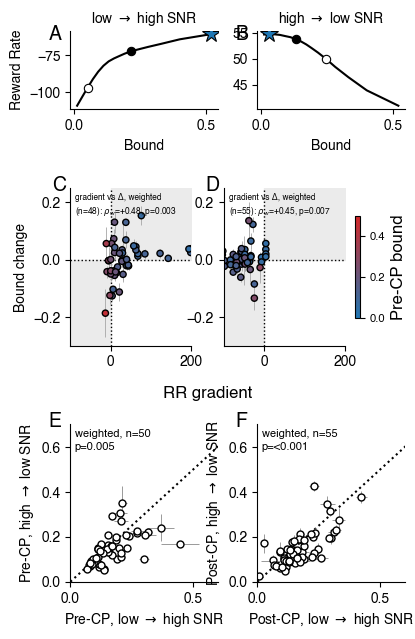

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure06.pdf (+ .png)


In [8]:
# ── Publication layout matching MATLAB getPLOT_axes(6, 8.5, [2,4,4], {2,2,2}, 2.0, 1.0) ──
CM       = 1 / 2.54
WID      = 8.5
HTS      = [2.0, 4.0, 4.0]
PSH      = 2.0
PSW      = 1.0
FS       = 12
HEADER_H = 0.6   # cm reserved above Row 1 for the column headers
GRAD_XLIM = (-100, 200)   # shared by both Row 2 panels
YLIM     = (-0.30, 0.25)
PRE_VMIN, PRE_VMAX = 0.0, 0.5

fig_h    = sum(HTS) + PSH * (len(HTS) - 1) + HEADER_H   # 2+4+4 + 2*2 + 0.6 = 14.6 cm
panel_w  = (WID - PSW) / 2                                # 3.75 cm
grid_top = 1 - HEADER_H / fig_h

fig_fmt = plt.figure(figsize=(WID * CM, fig_h * CM))
gs = gridspec.GridSpec(
    3, 2, figure=fig_fmt,
    height_ratios=HTS,
    hspace=PSH / np.mean(HTS),
    wspace=PSW / panel_w,
    left=0, right=1, bottom=0, top=grid_top,
)
axs_fmt = np.array([[fig_fmt.add_subplot(gs[r, c]) for c in range(2)] for r in range(3)])
plt.rcParams.update({'font.size': FS, 'axes.labelsize': FS, 'axes.titlesize': FS, **FONT_RC})

# ── Column headers ────────────────────────────────────────────────────────────
fig_fmt.canvas.draw()
header_y = grid_top + (1 - grid_top) / 2
col_titles = [r'low $\rightarrow$ high SNR', r'high $\rightarrow$ low SNR']
for tt in range(2):
    x_c = np.mean([axs_fmt[0, tt].get_position().x0, axs_fmt[0, tt].get_position().x1])
    fig_fmt.text(x_c, header_y, col_titles[tt], ha='center', va='center', fontsize=10)

# ── Row 1: example subject RR curve ──────────────────────────────────────────
# pre-CP bound = open (white) circle, post-CP bound = filled black circle — shape
# (not color) distinguishes the two, since Row 1 doesn't encode a continuous
# quantity the way Rows 2 and 3 do. Optimal bound stays a blue star throughout.
for tt in range(2):
    xs  = lh_bounds[:, 0] if tt == 0 else hl_bounds[:, 0]
    ys  = lh_bounds[:, 1] if tt == 0 else hl_bounds[:, 1]
    cpt = cp_lh             if tt == 0 else cp_hl
    pp  = EXAMPLE_SUBJECTS[tt]

    prei       = int(np.clip(np.searchsorted(BOUNDS, xs[pp], 'right') - 1, 0, len(BOUNDS) - 1))
    posti      = int(np.clip(np.searchsorted(BOUNDS, ys[pp], 'right') - 1, 0, len(BOUNDS) - 1))
    cp_idx_arr = np.where(cp_steps_by_cond[tt] == cpt[pp])[0]
    cp_idx     = int(cp_idx_arr[0]) if len(cp_idx_arr) else 0

    rrs    = pmats[tt][prei, :, cp_idx]
    kernel = np.ones(3) / 3
    rrs_sm = np.convolve(rrs, kernel, mode='same')
    rrs_sm[[0, -1]] = rrs[[0, -1]]
    maxi_sm = int(np.nanargmax(rrs_sm))  # smoothed argmax for display marker

    ax1 = axs_fmt[0, tt]
    ax1.plot(BOUNDS, rrs_sm, 'k-')
    ax1.plot(BOUNDS[prei],    rrs_sm[prei],    'o', markerfacecolor='white',
             markersize=6, markeredgecolor='k', markeredgewidth=0.8)
    ax1.plot(BOUNDS[maxi_sm], rrs_sm[maxi_sm], '*', color='tab:blue',
             markersize=13, markeredgecolor='k', markeredgewidth=0.8)
    ax1.plot(BOUNDS[posti],   rrs_sm[posti],   'o', markerfacecolor='black',
             markersize=6, markeredgecolor='k', markeredgewidth=0.8)
    ax1.set_xlabel('Bound')
    if tt == 0:
        ax1.set_ylabel('Reward Rate')
    add_panel_label(ax1, chr(65 + tt))

# ── Row 2: bound change vs. RR gradient ──────────────────────────────────────
# Fill color = pre-CP bound on a dedicated blue-red gradient (PRE_BOUND_CMAP).
# Points use a single, uniform edge color (not split or colored by gradient
# direction), including subjects at gradient == 0 (a legitimate value, not
# excluded; see the RR-benchmark and stats cells above). Each panel is annotated
# with the precision-weighted Spearman correlation (permutation p-value; see the
# stats cell above). Vertical error bars show each subject's SEM on Δ.
def _p(p):
    if not np.isfinite(p):
        return "n/a"
    return f"{p:.3f}" if p >= 0.001 else "<0.001"

for tt in range(2):
    d, grad, pre, sem_d = all_deltas[tt], all_gradient[tt], all_pre[tt], all_sem_delta[tt]
    fin = np.isfinite(d) & np.isfinite(grad) & np.isfinite(pre)
    d, grad, pre, sem_d = d[fin], grad[fin], pre[fin], sem_d[fin]

    ax2 = axs_fmt[1, tt]
    ax2.fill_between([GRAD_XLIM[0], 0], YLIM[0], 0, color='0.92', zorder=0)
    ax2.fill_between([0, GRAD_XLIM[1]], 0, YLIM[1], color='0.92', zorder=0)
    ax2.axhline(0, color='k', linestyle=':', linewidth=1, zorder=1)
    ax2.axvline(0, color='k', linestyle=':', linewidth=1, zorder=1)

    # Vertical error bars = per-subject SEM on Δ (sqrt(SEM_pre² + SEM_post²)),
    # drawn under the scatter so the fill color stays legible; a subject with an
    # undefined SEM (one trial on one side of the split -- ddof=0) simply gets no
    # bar rather than being dropped from the scatter.
    has_sem = np.isfinite(sem_d) & (sem_d > 0)
    ax2.errorbar(grad[has_sem], d[has_sem], yerr=sem_d[has_sem], fmt='none',
                 ecolor='0.65', elinewidth=0.6, capsize=0, zorder=1.5)

    sc = ax2.scatter(grad, d, c=pre, cmap=PRE_BOUND_CMAP,
                      vmin=PRE_VMIN, vmax=PRE_VMAX, edgecolors='black',
                      linewidths=1.0, s=20, zorder=2)

    ws = weighted_spearman_stats[TITLES[tt]]
    annot = (f"gradient vs Δ, weighted\n"
             f"(n={ws['n']}): $\\rho_w$={ws['rho']:+.2f}, p={_p(ws['p'])}")
    ax2.text(0.04, 0.97, annot, transform=ax2.transAxes, ha='left', va='top',
             fontsize=FS - 6, linespacing=1.3)

    ax2.set_xlim(GRAD_XLIM)
    ax2.set_ylim(YLIM)
    add_panel_label(ax2, chr(67 + tt))

ax_row2_bottom = min(axs_fmt[1, 0].get_position().y0, axs_fmt[1, 1].get_position().y0)
axs_fmt[1, 0].set_ylabel('Bound change')
cbar = fig_fmt.colorbar(sc, ax=list(axs_fmt[1, :]), shrink=0.65, pad=0.03)
cbar.set_label('Pre-CP bound', fontsize=FS)
cbar.ax.tick_params(labelsize=FS - 4)

fig_fmt.canvas.draw()
x_c = np.mean([axs_fmt[1, 0].get_position().x0, axs_fmt[1, 1].get_position().x1])
fig_fmt.text(x_c, ax_row2_bottom - 0.07, 'RR gradient', ha='center',
             va='top', fontsize=FS)

# ── Row 3: panel E (pre-CP) and panel F (post-CP), LowHigh vs. HighLow ──────
# Same two conditions in both panels -- pre- vs. post-changepoint bound -- so
# axis limits/labels/style match between them, making the two directly
# comparable. Errorbars = per-subject SEM (x: LowHigh, y: HighLow). Annotation
# is the precision-weighted paired-difference permutation test (panelEF_stats,
# computed in the stats cell above).
row3_specs = [
    ('E', axs_fmt[2, 0], lh_bounds[:, 0], hl_bounds[:, 0], sem_lh[:, 0], sem_hl[:, 0],
     'Pre-CP', panelEF_stats['E (pre-CP)']),
    ('F', axs_fmt[2, 1], lh_bounds[:, 1], hl_bounds[:, 1], sem_lh[:, 1], sem_hl[:, 1],
     'Post-CP', panelEF_stats['F (post-CP)']),
]
for label, ax, xs, ys, xerr, yerr, timepoint, stats in row3_specs:
    Lg = np.isfinite(xs) & np.isfinite(ys)
    ax.plot([0, 0.8], [0, 0.8], 'k:')
    ax.errorbar(xs[Lg], ys[Lg], xerr=xerr[Lg], yerr=yerr[Lg], fmt='o',
                markerfacecolor='white', markeredgecolor='k', markersize=5,
                ecolor='0.6', elinewidth=0.7, capsize=0, zorder=2)
    ax.text(0.03, 0.97, f"weighted, n={stats['n']}\np={_p(stats['p'])}",
            transform=ax.transAxes, ha='left', va='top', fontsize=FS - 4, linespacing=1.3)
    add_panel_label(ax, label)
    ax.set_xlabel(f'{timepoint}, low ' + r'$\rightarrow$' + ' high SNR')
    ax.set_ylabel(f'{timepoint}, high ' + r'$\rightarrow$' + ' low SNR')
    ax.set_xlim(0, 0.6)
    ax.set_ylim(0, 0.7)

for ax in axs_fmt.flat:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

out = FIGURES_DIR / 'Figure06.pdf'
fig_fmt.savefig(out, dpi=300, bbox_inches='tight')
fig_fmt.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')


In [9]:
# ── Row 2 (panels C, D) stats, printed at readable size ─────────────────────
# The panel annotations above use a small font (fontsize=FS-6, ~6pt) to fit
# inside the panel -- same numbers, printed here for readability.
for tt in range(2):
    ws = weighted_spearman_stats[TITLES[tt]]
    print(f"{TITLES[tt]} (panel {chr(67 + tt)}): gradient vs Δ, precision-weighted "
          f"Spearman rho_w={ws['rho']:+.3f}, permutation p={ws['p']:.4f} (n={ws['n']})")


LowHigh (panel C): gradient vs Δ, precision-weighted Spearman rho_w=+0.477, permutation p=0.0026 (n=48)
HighLow (panel D): gradient vs Δ, precision-weighted Spearman rho_w=+0.449, permutation p=0.0067 (n=55)


## Full-sample summary: included and reconstructed subjects

Panels C/D above use the `ok` subgroup (usable everywhere, which now includes subjects already at
the RR-optimal pre-CP bound -- gradient == 0.0 is a legitimate value there, not a missing one; see
above). The cells below characterize the remaining excluded subgroups from the "Data exclusion
summary" table so every subject is accounted for, then assemble everything into one summary table:

- **Included (`ok`)**: the precision-weighted gradient-vs-Δ regression from above.
- **Nonfinite bound**: subjects missing one side of the pre-/post-change split entirely (their
  RT never lands on the other side of the change point in any trial). Reconstructed
  with a proxy: the missing side's bound is substituted from the matching *fixed* block (Low/High,
  no-CP), which correlates ρ=0.64–0.79 with the real within-CP-block estimate among subjects who
  have both sides. Not used for the main stats above -- only for this subgroup check. A subject
  can still fail to reconstruct if the needed fixed-block bound or CP step is itself unusable;
  those are reported explicitly, not silently dropped.
- **Missing RR grid / no-fire switch**: too few subjects (or, for no-fire-switch, no CP-block data
  at all) to test -- reported as counts only.


In [10]:
# ── Reconstruct gradient/Δ for `nonfinite_bound` subjects via fixed-block proxy ──
# pre-CP proxy  = fixed block at the pre-switch SNR  (Low for LowHigh, High for HighLow)
# post-CP proxy = fixed block at the post-switch SNR (High for LowHigh, Low for HighLow)
FIXED_PRE  = [lo_bounds, hi_bounds]
FIXED_POST = [hi_bounds, lo_bounds]

def _gradient_at(bound_val, cp_idx, rmat):
    prei = int(np.clip(np.searchsorted(BOUNDS, bound_val, 'right') - 1, 0, len(BOUNDS) - 1))
    rrs  = rmat[prei, :, cp_idx]
    maxi = int(np.nanargmax(rrs))
    d_bound = BOUNDS[maxi] - BOUNDS[prei]
    return (rrs[maxi] - rrs[prei]) / d_bound if abs(d_bound) > 1e-9 else 0.0

subject_ids = np.sort(data_table_mxsc['subject_index'].dropna().unique())

reconstructed = [None, None]   # per condition: list of dict(subject_id, kind, gradient, delta)
for tt in range(2):
    xs  = lh_bounds[:, 0] if tt == 0 else hl_bounds[:, 0]
    ys  = lh_bounds[:, 1] if tt == 0 else hl_bounds[:, 1]
    cpt = cp_lh if tt == 0 else cp_hl
    fixed_pre  = FIXED_PRE[tt][:, 0]
    fixed_post = FIXED_POST[tt][:, 0]
    is_nf = all_reason[tt] == 'nonfinite_bound'

    rows = []
    for pp in np.where(is_nf)[0]:
        sid = int(subject_ids[pp])
        no_pre  = np.isnan(xs[pp]) and np.isfinite(ys[pp])
        no_post = np.isfinite(xs[pp]) and np.isnan(ys[pp])

        cp_idx_arr = np.where(cp_steps_by_cond[tt] == cpt[pp])[0]
        if not len(cp_idx_arr):
            print(f"{TITLES[tt]}: subject {sid} not reconstructable -- "
                  f"CP step {cpt[pp]:.0f} not in RRMats.mat grid")
            continue
        cp_idx = int(cp_idx_arr[0])

        if no_pre:
            if not np.isfinite(fixed_pre[pp]):
                print(f"{TITLES[tt]}: subject {sid} not reconstructable -- "
                      f"no usable fixed pre-switch-SNR block bound")
                continue
            g = _gradient_at(fixed_pre[pp], cp_idx, pmats[tt])
            d = ys[pp] - fixed_pre[pp]
            rows.append(dict(subject_id=sid, kind='no_pre', gradient=g, delta=d))
        elif no_post:
            if not np.isfinite(fixed_post[pp]):
                print(f"{TITLES[tt]}: subject {sid} not reconstructable -- "
                      f"no usable fixed post-switch-SNR block bound")
                continue
            g = _gradient_at(xs[pp], cp_idx, pmats[tt])
            d = fixed_post[pp] - xs[pp]
            rows.append(dict(subject_id=sid, kind='no_post', gradient=g, delta=d))
        else:
            print(f"{TITLES[tt]}: subject {sid} not reconstructable -- "
                  f"both pre- and post-CP bound are unusable")

    reconstructed[tt] = rows
    print(f"{TITLES[tt]}: reconstructed {len(rows)}/{int(is_nf.sum())} nonfinite_bound subjects\n")


LowHigh: reconstructed 10/10 nonfinite_bound subjects

HighLow: reconstructed 5/5 nonfinite_bound subjects



In [11]:
# ── nonfinite_bound subgroup (reconstructed): gradient level + Δ-vs-0 test ──
# Δ is tested with the same RR-gradient-sign adjustment as the main HighLow test
# (delta * sign(gradient)), so it's on the same footing as the included group's
# stats above -- LowHigh's adjustment is a near no-op since its reconstructed
# gradients are almost all positive, same as in the main sample.
nonfinite_stats = {}
for tt in range(2):
    rows = reconstructed[tt]
    if not rows:
        nonfinite_stats[TITLES[tt]] = dict(n=0)
        print(f"{TITLES[tt]}: no reconstructable nonfinite_bound subjects")
        continue
    g = np.array([r['gradient'] for r in rows])
    d = np.array([r['delta'] for r in rows])
    adj = np.where(g != 0, d * np.sign(g), np.nan)   # undefined sign at g==0, matches main convention
    adj = adj[np.isfinite(adj)]
    stat, p = scipy.stats.wilcoxon(adj) if len(adj) else (np.nan, np.nan)
    n_up, n_down = (int((adj > 0).sum()), int((adj < 0).sum())) if len(adj) else (0, 0)
    nonfinite_stats[TITLES[tt]] = dict(n=len(rows), median_gradient=np.median(g),
                                        median_delta_adj=np.median(adj) if len(adj) else np.nan,
                                        p=p, n_up=n_up, n_down=n_down)
    print(f"{TITLES[tt]} reconstructed nonfinite_bound (n={len(rows)}): "
          f"median gradient={np.median(g):+.1f}, median adj. Δ={np.median(adj) if len(adj) else np.nan:+.4f}, "
          f"Wilcoxon p={p:.4f} ({n_up} up / {n_down} down)")


LowHigh reconstructed nonfinite_bound (n=10): median gradient=+106.7, median adj. Δ=+0.0799, Wilcoxon p=0.0059 (9 up / 1 down)
HighLow reconstructed nonfinite_bound (n=5): median gradient=-25.9, median adj. Δ=+0.0198, Wilcoxon p=0.8125 (3 up / 2 down)


## Audit: initial bounds, fixed blocks vs. CP-block pre-CP bound

The manuscript also claims: "we also verified that the initial bounds used by participants were
similar for the same initial SNRs, regardless of the presence or absence of a changepoint...
between low-SNR fixed blocks and low→high changepoint blocks (Wilcoxon paired signed-rank test
for H0: equal medians, p=0.814) and between high-SNR and high→low changepoint blocks (p=0.098)."
This section computes that comparison (fixed-block bound, all trials, vs. the same subject's
pre-CP bound in the matching CP block) and folds it into "Key findings" and the comprehensive
table at the end of this notebook.


In [12]:
# ── "Initial bound" check referenced in the manuscript text ─────────────────
from pigeon.data import get_bound_summary

_low_fixed_all = np.asarray(get_bound_summary(
    data_table_mxsc.loc[data_table_mxsc['block_index'] == 1].reset_index(drop=True),
    blocks=1, max_rt='all', split_by_snr=False, subject_indices=subject_ids))[:, 0, 0, 0, 0]
_high_fixed_all = np.asarray(get_bound_summary(
    data_table_mxsc.loc[data_table_mxsc['block_index'] == 2].reset_index(drop=True),
    blocks=2, max_rt='all', split_by_snr=False, subject_indices=subject_ids))[:, 0, 0, 0, 0]

initial_bound_stats = {}
_ok1 = np.isfinite(_low_fixed_all) & np.isfinite(lh_bounds[:, 0])
_stat, _p1 = scipy.stats.wilcoxon(_low_fixed_all[_ok1], lh_bounds[_ok1, 0])
initial_bound_stats['LowHigh'] = dict(p=_p1, n=int(_ok1.sum()))

_ok2 = np.isfinite(_high_fixed_all) & np.isfinite(hl_bounds[:, 0])
_stat, _p2 = scipy.stats.wilcoxon(_high_fixed_all[_ok2], hl_bounds[_ok2, 0])
initial_bound_stats['HighLow'] = dict(p=_p2, n=int(_ok2.sum()))

print(f"Initial bound, Low-fixed vs LowHigh pre-CP:  n={initial_bound_stats['LowHigh']['n']}, "
      f"p={initial_bound_stats['LowHigh']['p']:.4f}  (manuscript: p=0.814)")
print(f"Initial bound, High-fixed vs HighLow pre-CP: n={initial_bound_stats['HighLow']['n']}, "
      f"p={initial_bound_stats['HighLow']['p']:.4f}  (manuscript: p=0.098)")


Initial bound, Low-fixed vs LowHigh pre-CP:  n=52, p=0.8412  (manuscript: p=0.814)
Initial bound, High-fixed vs HighLow pre-CP: n=56, p=0.0000  (manuscript: p=0.098)


## Comprehensive statistics table: every Figure-6 statistic + subgroup breakdown

One table combining every quantitative claim tied to Figure 6 in the manuscript Results section
(compared against this notebook's current computed output -- `Match` is `Yes` when values agree,
a short note when they differ, `n/a` for notebook-only diagnostics or panel designs the
manuscript text doesn't quote a directly comparable number for) with the per-condition subgroup
breakdown (every subject in both conditions, tallied by inclusion/exclusion reason -- previously
a separate table). Manuscript-comparison rows populate `Manuscript`/`Match`; subgroup rows leave
those `n/a` and use `Notes` instead.


In [13]:
# ── Combined table: manuscript-value comparison + subgroup breakdown ────────
import pandas as pd


def _fmt_p(p):
    return '<0.0001' if p < 0.0001 else f'{p:.4f}'


combined_rows = []

# CP timing
for tt, ms_val in zip(range(2), ['12.0 [7.0, 16.0]', '7.0 [5.0, 9.2]']):
    cpt = cp_lh if tt == 0 else cp_hl
    fin = np.isfinite(cpt)
    med, q1, q3 = np.nanpercentile(cpt[fin], [50, 25, 75])
    nb_val = f'{med:.1f} [{q1:.1f}, {q3:.1f}]'
    combined_rows.append(dict(Quantity='CP step timing (median [IQR], steps)', Condition=TITLES[tt],
                               N=int(fin.sum()), Notebook=nb_val, P=np.nan, Manuscript=ms_val,
                               Match='Yes' if nb_val == ms_val else 'CHECK', Notes=''))

# RR gradient
for tt, ms_val in zip(range(2), ['39.6 [17.1, 94.3]', '0.0 [-19.2, 58.4]']):
    g = all_gradient[tt]
    fin = np.isfinite(g)
    med, q1, q3 = np.percentile(g[fin], [50, 25, 75])
    nb_val = f'{med:.1f} [{q1:.1f}, {q3:.1f}]'
    combined_rows.append(dict(Quantity='RR gradient (median [IQR], coins/block/unit-bound-change)',
                               Condition=TITLES[tt], N=int(fin.sum()), Notebook=nb_val, P=np.nan,
                               Manuscript=ms_val, Match='Yes' if nb_val == ms_val else 'CHECK',
                               Notes=''))

# Panel C/D: precision-weighted Spearman correlation between gradient and Δ
for tt in range(2):
    ws = weighted_spearman_stats[TITLES[tt]]
    combined_rows.append(dict(
        Quantity='Panel C/D: gradient vs Δ, precision-weighted Spearman (rank-based, permutation p)',
        Condition=TITLES[tt], N=ws['n'], Notebook=f"rho_w={ws['rho']:+.3f}", P=ws['p'],
        Manuscript='Fig. 6 legend calls this a "precision-weighted ... Spearman\'s rho"',
        Match='Yes (methodology note: computed here as a rank-based weighted Pearson '
              'correlation on gradient and Δ, i.e. a weighted Spearman, with a permutation '
              'p-value)', Notes=''))

# Pre-CP bound vs delta (independent test, notebook-only -- not in manuscript text; unchanged)
for tt in range(2):
    sp = spearman_prebound[TITLES[tt]]
    combined_rows.append(dict(Quantity='Pre-CP bound vs Δ, Spearman rho (notebook-only check, unweighted)',
                               Condition=TITLES[tt], N=sp['n'], Notebook=f"rho={sp['rho']:+.3f}",
                               P=sp['p'], Manuscript='n/a', Match='n/a', Notes=''))

# Panels E (pre-CP) and F (post-CP): precision-weighted paired-difference permutation test
for label, ms_note in [
    ('E (pre-CP)', 'n/a (pre-CP LowHigh-vs-HighLow bound is not a plotted manuscript comparison; '
                    'shown here for direct comparison with panel F)'),
    ('F (post-CP)', 'p=0.002 (same LowHigh-vs-HighLow post-CP comparison the manuscript reports '
                     'as "Fig. 6E", there via a plain, unweighted Wilcoxon signed-rank test)'),
]:
    st = panelEF_stats[label]
    combined_rows.append(dict(
        Quantity='Panel E/F: LowHigh vs HighLow bound, precision-weighted paired-difference '
                 '(sign-flip permutation)',
        Condition=label, N=st['n'],
        Notebook=f"median Δ={st['median_diff']:+.4f}, weighted mean Δ={st['weighted_mean_diff']:+.4f}",
        P=st['p'], Manuscript=ms_note,
        Match=("Same qualitative conclusion (significant, LowHigh > HighLow bound)"
               ) if label == 'F (post-CP)' else
        'n/a (panel E is not a comparison the manuscript made)', Notes=''))

# Manuscript's Fig. 6F comparison (Low vs High stable-SNR blocks) is not computed by this
# notebook's panel F, which instead compares pre-/post-CP bound directly (see "Row 3" above
# for why: that comparison depends on an early/late trial-subset choice in get_bound_summary's
# median-split that flips its significance).
combined_rows.append(dict(
    Quantity='Manuscript Fig. 6F: Low vs High stable-SNR bound',
    Condition='Low vs High (stable blocks)', N=60, Notebook='n/a -- not computed by this notebook',
    P=np.nan, Manuscript='"not statistically distinguishable" (no p quoted in text)',
    Match='Open -- reconciling this with the manuscript is a separate task for the authors; '
          'panels E/F above compare pre-/post-CP bound directly instead', Notes=''))

# Initial bound checks
combined_rows.append(dict(Quantity='Initial bound: Low-fixed vs LowHigh pre-CP, Wilcoxon',
                           Condition='LowHigh', N=initial_bound_stats['LowHigh']['n'],
                           Notebook='', P=initial_bound_stats['LowHigh']['p'], Manuscript='p=0.814',
                           Match='Approx (data recollected since ms. written)', Notes=''))
combined_rows.append(dict(Quantity='Initial bound: High-fixed vs HighLow pre-CP, Wilcoxon',
                           Condition='HighLow', N=initial_bound_stats['HighLow']['n'],
                           Notebook='', P=initial_bound_stats['HighLow']['p'], Manuscript='p=0.098',
                           Match='NO -- significant, contradicts manuscript', Notes=''))

# Subgroup breakdown: every subject, both conditions, tallied by exclusion reason.
# Row n's do not sum to TOTAL by design: 'Included' n is the subset with a finite, positive
# SEM_Δ (a subject with only one trial on one side of the pre-/post-change split has a finite
# bound mean but an undefined SEM_Δ, so no weight can be formed), and 'Nonfinite bound' n is
# the reconstructable subset (a subject's CP step must be in RRMats.mat's grid to get even a
# proxy gradient) -- both gaps are called out per row in the Notes column below.
for tt in range(2):
    cond = TITLES[tt]

    ws = weighted_spearman_stats[cond]
    combined_rows.append(dict(
        Quantity='Subgroup: Included (usable everywhere)', Condition=cond, N=ws['n'],
        Notebook=f"gradient vs Δ, weighted Spearman rho_w={ws['rho']:+.2f}", P=ws['p'],
        Manuscript='n/a', Match='n/a', Notes=''))

    nf = nonfinite_stats[cond]
    n_nf_total = int((all_reason[tt] == 'nonfinite_bound').sum())
    combined_rows.append(dict(
        Quantity='Subgroup: Nonfinite bound (reconstructed proxy)', Condition=cond, N=nf.get('n', 0),
        Notebook=(f"median gradient={nf['median_gradient']:+.0f}, "
                  f"median adj. Δ={nf['median_delta_adj']:+.3f}") if nf.get('n', 0) else 'n/a',
        P=nf.get('p', np.nan), Manuscript='n/a', Match='n/a',
        Notes=((f"{nf['n_up']} up / {nf['n_down']} down"
                + (f"; {n_nf_total - nf['n']} of {n_nf_total} not reconstructable"
                   if nf['n'] != n_nf_total else ''))
               if nf.get('n', 0) else 'no reconstructable subjects')))

    n_mrg = int((all_reason[tt] == 'missing_rr_grid').sum())
    combined_rows.append(dict(Quantity='Subgroup: Missing RR grid', Condition=cond, N=n_mrg,
                               Notebook='n/a', P=np.nan, Manuscript='n/a', Match='n/a',
                               Notes='CP step not in RRMats.mat grid; too few to test'))

    n_nfs = int((all_reason[tt] == 'no_fire_switch').sum())
    combined_rows.append(dict(Quantity='Subgroup: No-fire switch', Condition=cond, N=n_nfs,
                               Notebook='n/a', P=np.nan, Manuscript='n/a', Match='n/a',
                               Notes='switch never fired online; no CP-block data'))

    combined_rows.append(dict(Quantity='Subgroup: TOTAL', Condition=cond, N=len(all_reason[tt]),
                               Notebook='', P=np.nan, Manuscript='', Match='', Notes=''))

combined_table = pd.DataFrame(combined_rows)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 220)
combined_table


,Quantity,Condition,N,Notebook,P,Manuscript,Match,Notes
0,"CP step timing (median [IQR], steps)",LowHigh,60,"12.0 [7.0, 16.0]",NaN,"12.0 [7.0, 16.0]",Yes,
1,"CP step timing (median [IQR], steps)",HighLow,60,"7.0 [5.0, 9.2]",NaN,"7.0 [5.0, 9.2]",Yes,
2,"RR gradient (median [IQR], coins/block/unit-bound-change)",LowHigh,50,"27.9 [6.2, 53.7]",NaN,"39.6 [17.1, 94.3]",CHECK,
3,"RR gradient (median [IQR], coins/block/unit-bound-change)",HighLow,55,"-56.0 [-70.4, -34.8]",NaN,"0.0 [-19.2, 58.4]",CHECK,
4,"Panel C/D: gradient vs Δ, precision-weighted Spearman (rank-based, permutation p)",LowHigh,48,rho_w=+0.477,0.002600,"Fig. 6 legend calls this a ""precision-weighted ... Spearman's rho""","Yes (methodology note: computed here as a rank-based weighted Pearson correlation on gradient and Δ, i.e. a weighted Spearman, with a permutation p-value)",
5,"Panel C/D: gradient vs Δ, precision-weighted Spearman (rank-based, permutation p)",HighLow,55,rho_w=+0.449,0.006699,"Fig. 6 legend calls this a ""precision-weighted ... Spearman's rho""","Yes (methodology note: computed here as a rank-based weighted Pearson correlation on gradient and Δ, i.e. a weighted Spearman, with a permutation p-value)",
6,"Pre-CP bound vs Δ, Spearman rho (notebook-only check, unweighted)",LowHigh,50,rho=-0.399,0.004102,n/a,n/a,
7,"Pre-CP bound vs Δ, Spearman rho (notebook-only check, unweighted)",HighLow,55,rho=-0.400,0.002461,n/a,n/a,
8,"Panel E/F: LowHigh vs HighLow bound, precision-weighted paired-difference (sign-flip permutation)",E (pre-CP),50,"median Δ=-0.0098, weighted mean Δ=-0.0146",0.004800,n/a (pre-CP LowHigh-vs-HighLow bound is not a plotted manuscript comparison; shown here for direct comparison with panel F),n/a (panel E is not a comparison the manuscript made),
9,"Panel E/F: LowHigh vs HighLow bound, precision-weighted paired-difference (sign-flip permutation)",F (post-CP),55,"median Δ=-0.0209, weighted mean Δ=-0.0252",0.000200,"p=0.002 (same LowHigh-vs-HighLow post-CP comparison the manuscript reports as ""Fig. 6E"", there via a plain, unweighted Wilcoxon signed-rank test)","Same qualitative conclusion (significant, LowHigh > HighLow bound)",


## Scratch: pre- vs. post-CP bound, LowHigh & HighLow (correct trials only)

Exploratory only. `lh_bounds`/`hl_bounds` and `sem_lh`/`sem_hl` are now correct-only (see "Load
data" above), so this plots each subject's pre-CP bound (x) against their post-CP bound (y),
errorbars = per-subject SEM in both directions, dotted diagonal = no change. Tests whether the
median of the paired differences (post - pre) is zero via a two-sided Wilcoxon signed-rank test
on each subject's post - pre difference, rather than testing a correlation between pre- and
post-CP bound.


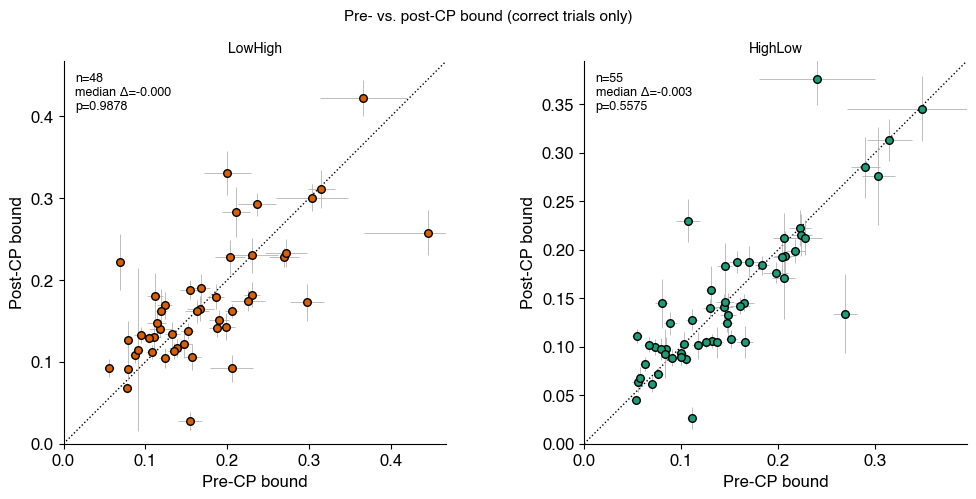

LowHigh: n=48, median(post-pre)=-0.000, Wilcoxon signed-rank p=0.9878
HighLow: n=55, median(post-pre)=-0.003, Wilcoxon signed-rank p=0.5575


In [14]:
def _plot_pre_vs_post(ax, bounds, sem_bounds, color, label):
    x, y = bounds[:, 0], bounds[:, 1]
    xerr, yerr = sem_bounds[:, 0], sem_bounds[:, 1]
    fin = (np.isfinite(x) & np.isfinite(y) & np.isfinite(xerr) & np.isfinite(yerr) & (yerr > 0))
    x_f, y_f, xerr_f, yerr_f = x[fin], y[fin], xerr[fin], yerr[fin]
    diff = y_f - x_f
    med_diff = np.median(diff)
    p_med = scipy.stats.wilcoxon(diff).pvalue

    lim = max(np.nanmax(x_f), np.nanmax(y_f)) * 1.05
    ax.plot([0, lim], [0, lim], 'k:', linewidth=1, zorder=0)
    ax.errorbar(x_f, y_f, xerr=xerr_f, yerr=yerr_f, fmt='none', ecolor='0.7',
                elinewidth=0.6, capsize=0, zorder=1.5)
    ax.scatter(x_f, y_f, facecolor=color, edgecolor='k', s=30, zorder=2)
    ax.text(0.03, 0.97, f'n={len(x_f)}\nmedian \u0394={med_diff:+.3f}\np={p_med:.4f}',
            transform=ax.transAxes, ha='left', va='top', fontsize=9)
    ax.set_xlabel('Pre-CP bound')
    ax.set_ylabel('Post-CP bound')
    ax.set_title(label, fontsize=10)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_aspect('equal')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    return med_diff, p_med, len(x_f)


fig5, (ax5a, ax5b) = plt.subplots(1, 2, figsize=(10.5, 5))
med_lh, p_lh, n_lh = _plot_pre_vs_post(ax5a, lh_bounds, sem_lh, '#d95f02', 'LowHigh')
med_hl, p_hl, n_hl = _plot_pre_vs_post(ax5b, hl_bounds, sem_hl, '#1b9e77', 'HighLow')
fig5.suptitle('Pre- vs. post-CP bound (correct trials only)', fontsize=11)

plt.tight_layout()
plt.show()

print(f'LowHigh: n={n_lh}, median(post-pre)={med_lh:+.3f}, Wilcoxon signed-rank p={p_lh:.4f}')
print(f'HighLow: n={n_hl}, median(post-pre)={med_hl:+.3f}, Wilcoxon signed-rank p={p_hl:.4f}')


## Scratch: per-subject linear model of |bound| vs. trial number and DT

For each subject and each block type (`Low`, `High`, `LowHigh`, `HighLow`), fit an OLS model to
that subject's trials in that block:

    abs_bound ~ 1 + trial_number + DT

`data_table_mxsc` is already correct-trials-only and `trial_number > 10` (see "Load data" above);
`DT > 1` is applied here on top of that. Subjects with fewer than `MIN_TRIALS_LM` qualifying
trials in a block get `NaN` coefficients rather than being dropped, so every result stays indexed
by `subject_ids`.

Below: scatters of the DT term across block types -- LowHigh vs. HighLow (the two change-point
block types), and Low vs. High (the two stable fixed-SNR block types). Each panel tests whether
the median of the paired, subject-matched difference in DT coefficient is zero (two-sided
Wilcoxon signed-rank test), rather than testing a correlation between the two conditions.


In [15]:
# ── Fit |bound| ~ 1 + trial_number + DT, per subject and per block type ─────────
LM_BLOCKS     = {'Low': 1, 'High': 2, 'LowHigh': 3, 'HighLow': 4}
LM_TERMS      = ['offset', 'trial_number', 'DT']
MIN_TRIALS_LM = 5

lm_coefs = {name: np.full((len(subject_ids), len(LM_TERMS)), np.nan) for name in LM_BLOCKS}

for name, block_index in LM_BLOCKS.items():
    block_data = data_table_mxsc[data_table_mxsc['block_index'] == block_index]
    for si, subj in enumerate(subject_ids):
        sub = block_data[(block_data['subject_index'] == subj) & (block_data['DT'] > 1)]
        y = sub['abs_bound'].to_numpy()
        X = np.column_stack([np.ones(len(sub)), sub['trial_number'].to_numpy(), sub['DT'].to_numpy()])
        fin = np.isfinite(y) & np.all(np.isfinite(X), axis=1)
        if fin.sum() < MIN_TRIALS_LM:
            continue
        lm_coefs[name][si], *_ = np.linalg.lstsq(X[fin], y[fin], rcond=None)

for name in LM_BLOCKS:
    n_ok = np.isfinite(lm_coefs[name][:, 2]).sum()
    print(f"{name:8s}: {n_ok}/{len(subject_ids)} subjects fit, "
          f"mean DT coef={np.nanmean(lm_coefs[name][:, 2]):+.4f}")


Low     : 64/65 subjects fit, mean DT coef=+0.0004
High    : 61/65 subjects fit, mean DT coef=+0.0036
LowHigh : 60/65 subjects fit, mean DT coef=+0.0004
HighLow : 60/65 subjects fit, mean DT coef=+0.0004


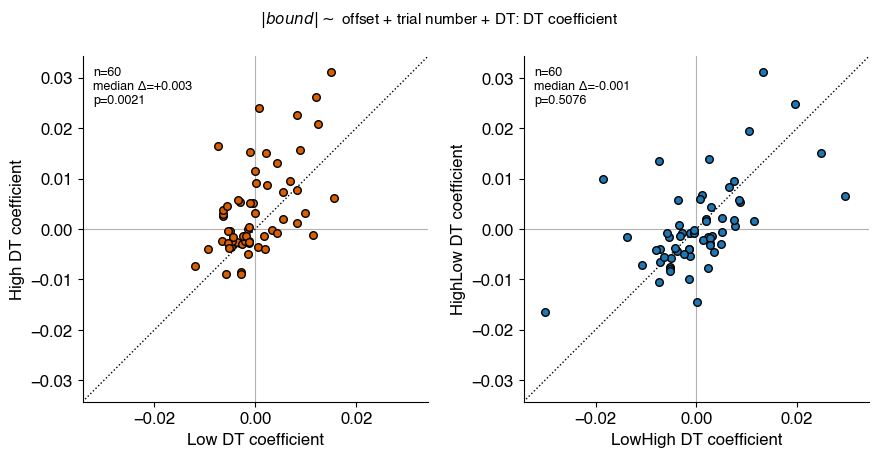

Low vs High: n=60, median(High-Low)=+0.0025, Wilcoxon signed-rank p=0.0021
LowHigh vs HighLow: n=60, median(HighLow-LowHigh)=-0.0005, Wilcoxon signed-rank p=0.5076


In [16]:
# ── DT-term scatter: LowHigh vs. HighLow, and Low vs. High ───────────────────────────
def _dt_scatter(ax, name_x, name_y, color):
    x, y = lm_coefs[name_x][:, 2], lm_coefs[name_y][:, 2]
    fin = np.isfinite(x) & np.isfinite(y)
    lim = np.nanmax(np.abs(np.concatenate([x[fin], y[fin]]))) * 1.1

    ax.axhline(0, color='0.7', linewidth=0.8, zorder=0)
    ax.axvline(0, color='0.7', linewidth=0.8, zorder=0)
    ax.plot([-lim, lim], [-lim, lim], 'k:', linewidth=1, zorder=1)
    ax.scatter(x[fin], y[fin], facecolor=color, edgecolor='k', s=30, zorder=2)

    diff = y[fin] - x[fin]
    med_diff = np.median(diff)
    p_med = scipy.stats.wilcoxon(diff).pvalue
    ax.text(0.03, 0.97, f'n={fin.sum()}\nmedian \u0394={med_diff:+.3f}\np={p_med:.4f}',
            transform=ax.transAxes, ha='left', va='top', fontsize=9)
    ax.set_xlabel(f'{name_x} DT coefficient')
    ax.set_ylabel(f'{name_y} DT coefficient')
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect('equal')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    return med_diff, p_med, int(fin.sum())


fig_lm, (ax_lm1, ax_lm2) = plt.subplots(1, 2, figsize=(9, 4.5))
# med_l, p_l, n_l = _dt_scatter(ax_lm1, 'Low', 'LowHigh', '#d95f02')
# med_h, p_h, n_h = _dt_scatter(ax_lm2, 'High', 'HighLow', 'tab:blue')
med_ctl, p_ctl, n_ctl = _dt_scatter(ax_lm1, 'Low', 'High', '#d95f02')
med_cp, p_cp, n_cp = _dt_scatter(ax_lm2, 'LowHigh', 'HighLow', 'tab:blue')
fig_lm.suptitle(r'$|bound| \sim$ offset + trial number + DT: DT coefficient', fontsize=11)
plt.tight_layout()
plt.show()

print(f'Low vs High: n={n_ctl}, median(High-Low)={med_ctl:+.4f}, Wilcoxon signed-rank p={p_ctl:.4f}')
print(f'LowHigh vs HighLow: n={n_cp}, median(HighLow-LowHigh)={med_cp:+.4f}, Wilcoxon signed-rank p={p_cp:.4f}')


## Scratch: DT-only fit on running-average-detrended, z-scored bound residuals

Alternative to the `abs_bound ~ 1 + trial_number + DT` model above. Instead of using a linear
`trial_number` term to absorb each block's slow within-block drift, this detrends first and fits
DT alone:

1. Same per-subject, per-block trial selection as above (`data_table_mxsc`, `DT > 1`, trials
   ordered by `trial_number`).
2. Subtract a 10-trial centered running average (`RESID_WINDOW`, `pandas.Series.rolling`) from
   `abs_bound` to get a detrended residual.
3. z-score that residual (per subject/block, so every subject's residual sits on the same
   standard-deviation scale regardless of their raw bound magnitude).
4. Fit `residual_z ~ 1 + DT` (`LM2_TERMS`) -- two terms instead of three, since the running-average
   subtraction already removes the slow trend `trial_number` was standing in for above.

Same panels, same test as the `trial_number`+DT model: the DT coefficient scattered LowHigh vs.
HighLow and Low vs. High, each tested for whether the median of the paired, subject-matched
difference is zero (two-sided Wilcoxon signed-rank test).


In [17]:
# ── Detrend abs_bound with a 10-trial running average, z-score the residual, then
# fit residual_z ~ 1 + DT (two terms) per subject and per block type ────────────
import pandas as pd

RESID_WINDOW = 10
LM2_TERMS    = ['offset', 'DT']

lm_coefs_resid = {name: np.full((len(subject_ids), len(LM2_TERMS)), np.nan) for name in LM_BLOCKS}

for name, block_index in LM_BLOCKS.items():
    block_data = data_table_mxsc[data_table_mxsc['block_index'] == block_index]
    for si, subj in enumerate(subject_ids):
        sub = block_data[(block_data['subject_index'] == subj) & (block_data['DT'] > 1)]
        sub = sub.sort_values('trial_number')
        y = sub['abs_bound'].to_numpy()
        dts = sub['DT'].to_numpy()
        fin = np.isfinite(y) & np.isfinite(dts)
        if fin.sum() < MIN_TRIALS_LM:
            continue
        y, dts = y[fin], dts[fin]

        running_avg = (pd.Series(y)
                       .rolling(RESID_WINDOW, center=True, min_periods=1)
                       .mean()
                       .to_numpy())
        resid = y - running_avg
        resid_std = resid.std()
        if not np.isfinite(resid_std) or resid_std == 0:
            continue
        resid_z = (resid - resid.mean()) / resid_std

        X = np.column_stack([np.ones(len(resid_z)), dts])
        lm_coefs_resid[name][si], *_ = np.linalg.lstsq(X, resid_z, rcond=None)

for name in LM_BLOCKS:
    n_ok = np.isfinite(lm_coefs_resid[name][:, 1]).sum()
    print(f"{name:8s}: {n_ok}/{len(subject_ids)} subjects fit, "
          f"mean DT coef={np.nanmean(lm_coefs_resid[name][:, 1]):+.4f}")


Low     : 64/65 subjects fit, mean DT coef=-0.0068
High    : 61/65 subjects fit, mean DT coef=+0.0135
LowHigh : 60/65 subjects fit, mean DT coef=-0.0068
HighLow : 60/65 subjects fit, mean DT coef=-0.0070


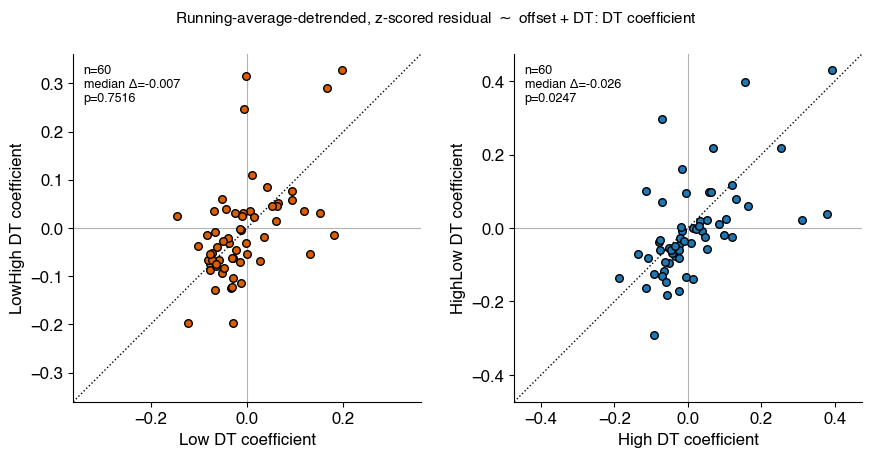

Low vs LowHigh: n=60, median(LowHigh-Low)=-0.0067, Wilcoxon signed-rank p=0.7516
High vs HighLow: n=60, median(HighLow-High)=-0.0265, Wilcoxon signed-rank p=0.0247


In [18]:
# ── DT-term scatter (residual model): LowHigh vs. HighLow, and Low vs. High ──────────
def _dt_scatter_resid(ax, name_x, name_y, color):
    x, y = lm_coefs_resid[name_x][:, 1], lm_coefs_resid[name_y][:, 1]
    fin = np.isfinite(x) & np.isfinite(y)
    lim = np.nanmax(np.abs(np.concatenate([x[fin], y[fin]]))) * 1.1

    ax.axhline(0, color='0.7', linewidth=0.8, zorder=0)
    ax.axvline(0, color='0.7', linewidth=0.8, zorder=0)
    ax.plot([-lim, lim], [-lim, lim], 'k:', linewidth=1, zorder=1)
    ax.scatter(x[fin], y[fin], facecolor=color, edgecolor='k', s=30, zorder=2)

    diff = y[fin] - x[fin]
    med_diff = np.median(diff)
    p_med = scipy.stats.wilcoxon(diff).pvalue
    ax.text(0.03, 0.97, f'n={fin.sum()}\nmedian \u0394={med_diff:+.3f}\np={p_med:.4f}',
            transform=ax.transAxes, ha='left', va='top', fontsize=9)
    ax.set_xlabel(f'{name_x} DT coefficient')
    ax.set_ylabel(f'{name_y} DT coefficient')
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect('equal')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    return med_diff, p_med, int(fin.sum())


fig_lm_resid, (ax_lmr1, ax_lmr2) = plt.subplots(1, 2, figsize=(9, 4.5))
med_l_r, p_l_r, n_l_r = _dt_scatter_resid(ax_lmr1, 'Low', 'LowHigh', '#d95f02')
med_h_r, p_h_r, n_h_r = _dt_scatter_resid(ax_lmr2, 'High', 'HighLow', 'tab:blue')
fig_lm_resid.suptitle('Running-average-detrended, z-scored residual $\\sim$ offset + DT: '
                       'DT coefficient', fontsize=11)
plt.tight_layout()
plt.show()

print(f'Low vs LowHigh: n={n_l_r}, median(LowHigh-Low)={med_l_r:+.4f}, Wilcoxon signed-rank p={p_l_r:.4f}')
print(f'High vs HighLow: n={n_h_r}, median(HighLow-High)={med_h_r:+.4f}, Wilcoxon signed-rank p={p_h_r:.4f}')
